# PRÁCTICA 2 · RA1: Pipeline de Integración Multifuente
**Módulo:** M4 · Sistemes de Big Data  
**Resultado de Aprendizaje (RA1):** Integración, procesamiento y análisis de información  
**Alumno:** Daniel García Brun  
**Tecnologías:** Python 3 · Pandas · Requests · BeautifulSoup · PyArrow · Matplotlib  

---

### Resumen del Proyecto
ShopData S.L. es una empresa de comercio electrónico que almacena su información de negocio distribuida en tres fuentes heterogéneas:
1. **Fuente A (Ventas internas):** Archivo `shopdata_sales.csv` (~75.000 transacciones históricas).
2. **Fuente B (Catálogo de productos):** API REST pública (`https://dummyjson.com/products`).
3. **Fuente C (Precios de la competencia):** Archivo web `competitor_prices.html` (portal comparador PriceScope).

El objetivo de este notebook es construir un **pipeline de datos reproducible, robusto y automatizado** capaz de extraer, transformar, relacionar, validar y exportar la información integrada en un dataset analítico final en formato **Parquet** (`shopdata_analytical.parquet`), respondiendo a preguntas estratégicas de negocio.

## 0. Configuración del Entorno y Carga de Librerías
Importamos todas las dependencias necesarias para la extracción, manipulación de datos, scraping, validación y visualización.

In [1]:
import os
import re
import json
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

# Configuración de visualización en pandas y matplotlib
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## Parte 1: Inspección de las Fuentes — Fuente A: Ventas Internas
Cargamos el fichero histórico de transacciones `shopdata_sales.csv` en el DataFrame `df_sales` e inspeccionamos su estructura, tipología de datos, cobertura temporal, volumen y calidad.

In [2]:
# Carga del fichero CSV de ventas
csv_file_path = "shopdata_sales.csv"
df_sales = pd.read_csv(csv_file_path)

# Conversión de la columna date a tipo datetime para análisis temporal
df_sales['date'] = pd.to_datetime(df_sales['date'])

print("--- Inspección General de df_sales ---")
print(f"Dimensiones: {df_sales.shape[0]:,} filas x {df_sales.shape[1]} columnas")
print("\nTipos de datos y memoria:")
print(df_sales.dtypes)
print("\nPrimeras filas del DataFrame:")
display(df_sales.head())

--- Inspección General de df_sales ---
Dimensiones: 75,000 filas x 7 columnas

Tipos de datos y memoria:
sale_id                        str
date                datetime64[us]
product_id                   int64
units                        int64
unit_price                 float64
customer_country               str
channel                        str
dtype: object

Primeras filas del DataFrame:


,sale_id,date,product_id,units,unit_price,customer_country,channel
0,S0000001,2026-01-22 11:58:50,31,1,0.79,ES,app
1,S0000002,2026-08-08 15:14:19,122,1,262.30,ES,web
2,S0000003,2026-03-18 19:45:17,6,1,49.32,PT,app
3,S0000004,2026-03-19 02:20:25,121,1,193.09,DE,app
4,S0000005,2026-02-02 01:11:01,6,1,42.47,IT,web


In [3]:
# Análisis de cobertura temporal, unicidad y valores ausentes
print("Rango temporal de las ventas:")
print(f"  Fecha mínima: {df_sales['date'].min()}")
print(f"  Fecha máxima: {df_sales['date'].max()}")
print(f"  Periodo total cubierto: {(df_sales['date'].max() - df_sales['date'].min()).days} días")

print(f"\nProductos únicos en ventas: {df_sales['product_id'].nunique()}")
print(f"Listado de product_id presentes en ventas: {sorted(df_sales['product_id'].unique())}")

print("\nDistribución por canales de venta:")
channel_dist = pd.DataFrame({
    'Transacciones': df_sales['channel'].value_counts(),
    'Porcentaje (%)': (df_sales['channel'].value_counts(normalize=True) * 100).round(2)
})
display(channel_dist)

print("\nValores ausentes (nulos):")
display(df_sales.isnull().sum())

print("\nResumen estadístico de variables numéricas:")
display(df_sales[['units', 'unit_price']].describe())

Rango temporal de las ventas:
  Fecha mínima: 2026-01-01 00:01:08
  Fecha máxima: 2026-08-15 23:49:47
  Periodo total cubierto: 226 días

Productos únicos en ventas: 16
Listado de product_id presentes en ventas: [np.int64(1), np.int64(6), np.int64(31), np.int64(61), np.int64(91), np.int64(121), np.int64(122), np.int64(151), np.int64(152), np.int64(181), np.int64(193), np.int64(194), np.int64(9001), np.int64(9002), np.int64(9003), np.int64(9004)]

Distribución por canales de venta:


,Transacciones,Porcentaje (%)
channel,,
web,34517,46.02
app,25610,34.15
marketplace,8889,11.85
store,5984,7.98



Valores ausentes (nulos):


sale_id             0
date                0
product_id          0
units               0
unit_price          0
customer_country    0
channel             0
dtype: int64


Resumen estadístico de variables numéricas:


,units,unit_price
count,75000.00,75000.00
mean,1.60,124.53
std,0.95,159.37
min,1.00,0.65
25%,1.00,10.26
50%,1.00,51.59
75%,2.00,178.89
max,5.00,861.02


> **Hallazgos clave de la Fuente A:**
> - El dataset consta exactamente de **75.000 transacciones**.
> - El rango temporal comprende desde el **01/01/2026** hasta el **15/08/2026**.
> - Solo se venden **16 identificadores únicos de producto** a lo largo de todo el histórico.
> - El canal con mayor volumen de transacciones es la **Web (46,02%)**, seguido de la **App (34,15%)**, **Marketplace (11,85%)** y **Tienda física (7,98%)**.
> - No se detectan valores nulos en ninguna de las columnas.

## Parte 2: Consumo de la API REST — Fuente B: Catálogo de Productos
Consultamos la API REST pública de DummyJSON (`https://dummyjson.com/products`).
Como indica el enunciado:
1. No se debe asumir un número fijo de productos.
2. Se debe recuperar todo el catálogo dinámicamente mediante paginación con `limit` y `skip`.
3. Se incluye un mecanismo de contingencia para utilizar el respaldo `products_api_backup_subset.json` si la API pública no estuviera disponible.

In [4]:
# 2.1 Verificación inicial del endpoint
api_url = "https://dummyjson.com/products"
try:
    resp_init = requests.get(f"{api_url}?limit=5", timeout=10)
    print(f"Código HTTP recibido: {resp_init.status_code}")
    data_init = resp_init.json()
    print("Estructura de la respuesta JSON (claves principales):", list(data_init.keys()))
    print(f"Productos recibidos en esta petición: {len(data_init.get('products', []))}")
    print(f"Total reportado por la API: {data_init.get('total')}")
    print(f"Parámetros: limit={data_init.get('limit')}, skip={data_init.get('skip')}")
except Exception as e:
    print(f"Error en consulta inicial: {e}")

Código HTTP recibido: 200
Estructura de la respuesta JSON (claves principales): ['products', 'total', 'skip', 'limit']
Productos recibidos en esta petición: 5
Total reportado por la API: 194
Parámetros: limit=5, skip=0


In [5]:
# 2.2 Paginación automática dinámica y mecanismo de contingencia
def fetch_complete_catalog(base_url="https://dummyjson.com/products", backup_path="products_api_backup_subset.json"):
    # Recupera todo el catálogo paginado leyendo dinámicamente el valor 'total'.
    # Si la API falla, recurre al fichero local de contingencia.
    products = []
    skip = 0
    batch_limit = 50  # Tamaño de lote razonable
    total = None
    
    try:
        print("Iniciando consumo paginado de la API REST...")
        while total is None or skip < total:
            url = f"{base_url}?limit={batch_limit}&skip={skip}"
            res = requests.get(url, timeout=10)
            if res.status_code != 200:
                raise RuntimeError(f"Código HTTP inusual: {res.status_code}")
            
            payload = res.json()
            total = payload.get("total", 0)
            batch = payload.get("products", [])
            
            if not batch:
                break
                
            products.extend(batch)
            print(f" -> Lote recuperado: skip={skip}, obtenidos={len(batch)}, acumulados={len(products)}/{total}")
            skip += len(batch)
            
        print(f"API consumida con éxito: {len(products)} productos descargados en total.")
        return pd.DataFrame(products)
        
    except Exception as err:
        print(f"[ALERTA CONTINGENCIA] Error al conectar con la API ({err}). Activando respaldo local...")
        with open(backup_path, 'r', encoding='utf-8') as f:
            backup_data = json.load(f)
        return pd.DataFrame(backup_data.get('products', []))

# Ejecución de la extracción del catálogo
df_raw_products = fetch_complete_catalog()
print(f"DataFrame crudo de productos: {df_raw_products.shape[0]} filas x {df_raw_products.shape[1]} columnas")

Iniciando consumo paginado de la API REST...


 -> Lote recuperado: skip=0, obtenidos=50, acumulados=50/194


 -> Lote recuperado: skip=50, obtenidos=50, acumulados=100/194


 -> Lote recuperado: skip=100, obtenidos=50, acumulados=150/194


 -> Lote recuperado: skip=150, obtenidos=44, acumulados=194/194
API consumida con éxito: 194 productos descargados en total.
DataFrame crudo de productos: 194 filas x 22 columnas


In [6]:
# 2.3 Selección de variables relevantes y conformación de df_products
selected_columns = ['id', 'title', 'category', 'price', 'rating', 'stock', 'brand', 'sku', 'availabilityStatus']

df_products = df_raw_products[[col for col in selected_columns if col in df_raw_products.columns]].copy()

# Renombrado de claves para coherencia analítica
df_products.rename(columns={'id': 'product_id', 'price': 'current_price'}, inplace=True)

print("--- Inspección de df_products ---")
print(f"Dimensiones: {df_products.shape[0]} productos x {df_products.shape[1]} columnas")
print(f"¿Es 'product_id' único?: {df_products['product_id'].is_unique}")
print(f"Valores nulos en catálogo:\n{df_products.isnull().sum()}")

print(f"\nProductos sin marca registrada (brand nulo): {df_products['brand'].isnull().sum()}")
print(f"Productos actualmente sin stock (stock == 0): {(df_products['stock'] == 0).sum()}")
print(f"Número de categorías disponibles: {df_products['category'].nunique()}")
print(f"\nMuestra de categorías:\n{df_products['category'].value_counts().head(8)}")
display(df_products.head())

--- Inspección de df_products ---
Dimensiones: 194 productos x 9 columnas
¿Es 'product_id' único?: True
Valores nulos en catálogo:
product_id             0
title                  0
category               0
current_price          0
rating                 0
stock                  0
brand                 92
sku                    0
availabilityStatus     0
dtype: int64

Productos sin marca registrada (brand nulo): 92
Productos actualmente sin stock (stock == 0): 4
Número de categorías disponibles: 24

Muestra de categorías:
category
kitchen-accessories    30
groceries              27
sports-accessories     17
smartphones            16
mobile-accessories     14
mens-watches            6
beauty                  5
fragrances              5
Name: count, dtype: int64


,product_id,title,category,current_price,rating,stock,brand,sku,availabilityStatus
0,1,Essence Mascara Lash Princess,beauty,9.99,2.56,99,Essence,BEA-ESS-ESS-001,In Stock
1,2,Eyeshadow Palette with Mirror,beauty,19.99,2.86,34,Glamour Beauty,BEA-GLA-EYE-002,In Stock
2,3,Powder Canister,beauty,14.99,4.64,89,Velvet Touch,BEA-VEL-POW-003,In Stock
3,4,Red Lipstick,beauty,12.99,4.36,91,Chic Cosmetics,BEA-CHI-LIP-004,In Stock
4,5,Red Nail Polish,beauty,8.99,4.32,79,Nail Couture,BEA-NAI-NAI-005,In Stock


## Parte 3: Web Scraping — Fuente C: Precios de la Competencia
Extraemos los datos de la página web `competitor_prices.html` del comparador de precios *PriceScope*.
El objetivo es recuperar automáticamente:
- Identificador del producto (`product_id`)
- Nombre del competidor
- Nombre mostrado del producto
- Precio de la oferta (normalizado a número `float`)
- Disponibilidad

In [7]:
html_file_path = "competitor_prices.html"

def scrape_competitor_offers(file_path):
    with open(file_path, "r", encoding="utf-8", errors="replace") as f:
        html_content = f.read()
        
    soup = BeautifulSoup(html_content, "html.parser")
    offer_cards = soup.find_all("article", class_="offer-card")
    
    extracted_records = []
    for card in offer_cards:
        # Extracción de atributos y elementos hijos
        raw_pid = card.get("data-product-id")
        comp_tag = card.find(class_="competitor")
        title_tag = card.find(class_="product-name")
        avail_tag = card.find(class_="availability")
        price_tag = card.find(class_="price")
        
        competitor = comp_tag.get_text(strip=True) if comp_tag else None
        name_displayed = title_tag.get_text(strip=True) if title_tag else None
        availability = avail_tag.get_text(strip=True) if avail_tag else None
        
        # 3.1 Tratamiento y normalización del precio:
        # Casos observados: "49,50 €", "€ 47,90", "49,50 EUR", "0,69 €"
        raw_price = price_tag.get_text(strip=True) if price_tag else ""
        clean_price_str = re.sub(r'[^0-9,\.]', '', raw_price).replace(',', '.').strip()
        numeric_price = float(clean_price_str) if clean_price_str else np.nan
        
        extracted_records.append({
            'product_id': int(raw_pid) if raw_pid else np.nan,
            'competitor': competitor,
            'competitor_product_name': name_displayed,
            'competitor_price': numeric_price,
            'availability': availability
        })
        
    return pd.DataFrame(extracted_records)

df_competitors = scrape_competitor_offers(html_file_path)

print("--- Inspección de df_competitors ---")
print(f"Total de ofertas extraídas mediante scraping: {len(df_competitors)}")
print(f"Competidores detectados: {df_competitors['competitor'].unique().tolist()}")
print(f"¿Es 'product_id' único en la competencia?: {df_competitors['product_id'].is_unique}")
print(f"Productos únicos con ofertas de competidores: {df_competitors['product_id'].nunique()}")
display(df_competitors.head(10))

--- Inspección de df_competitors ---
Total de ofertas extraídas mediante scraping: 31
Competidores detectados: ['CosmeticLab', 'PerfumeHub', 'MegaStore', 'UrbanFeet', 'PhoneOutlet', 'TechMarket', 'SuperPrice', 'BeautyZone', 'LuxuryTime', 'EcoBasket', 'ElectroWorld', 'WatchHouse', 'SportDeal', 'HomeTech', 'RacketPoint', 'FreshMarket', 'SneakerLab']
¿Es 'product_id' único en la competencia?: False
Productos únicos con ofertas de competidores: 12


,product_id,competitor,competitor_product_name,competitor_price,availability
0,1,CosmeticLab,Essence Lash Princess Mascara,9.49,Disponible
1,6,PerfumeHub,Calvin Klein CK ONE Eau de Toilette,47.90,En stock
2,152,MegaStore,Raqueta de tenis,49.50,Disponible
3,91,UrbanFeet,Off White / Red Sports Sneakers,124.90,Últimas unidades
4,193,MegaStore,Fashion Gold Women's Watch,799.95,Últimas unidades
5,122,PhoneOutlet,Apple iPhone 6,289.95,Disponible
6,121,TechMarket,Apple iPhone 5S,179.99,Reacondicionado
7,31,SuperPrice,Limón fresco unidad,0.75,Disponible
8,1,BeautyZone,Essence Lash Princess Mascara,8.89,En stock
9,193,LuxuryTime,Fashion Gold Women's Watch,749.00,Disponible bajo pedido


## Parte 4: Comprender las Relaciones y Cardinalidades
Antes de proceder con cualquier unión (`merge`), debemos caracterizar formalmente las claves primarias, foráneas y cardinalidades de las tres fuentes.

In [8]:
# Comprobaciones mediante código de unicidad y duplicados
print("--- COMPROBACIONES DE CLAVES ---")
print(f"1. Clave candidata en ventas (sale_id): is_unique = {df_sales['sale_id'].is_unique}")
print(f"2. product_id en df_sales: is_unique = {df_sales['product_id'].is_unique} | Total duplicados = {df_sales['product_id'].duplicated().sum():,}")
print(f"3. product_id en df_products: is_unique = {df_products['product_id'].is_unique} | Total duplicados = {df_products['product_id'].duplicated().sum()}")
print(f"4. product_id en df_competitors: is_unique = {df_competitors['product_id'].is_unique} | Total duplicados = {df_competitors['product_id'].duplicated().sum()}")

--- COMPROBACIONES DE CLAVES ---
1. Clave candidata en ventas (sale_id): is_unique = True
2. product_id en df_sales: is_unique = False | Total duplicados = 74,984
3. product_id en df_products: is_unique = True | Total duplicados = 0
4. product_id en df_competitors: is_unique = False | Total duplicados = 19


### Respuestas a las preguntas de relación:

1. **¿Cuál es la clave principal de las ventas?**
   - La clave principal es `sale_id`, ya que identifica unívocamente cada transacción individual (`is_unique = True`, 75.000 identificadores distintos sin repetición ni nulos).
2. **¿Qué variable permite relacionar una venta con un producto de la API?**
   - El identificador del producto: `product_id` en las ventas y `id` (renombrado a `product_id`) en el catálogo.
3. **¿Es `product_id` único en las ventas?**
   - **No**. Un mismo producto es adquirido en múltiples transacciones a lo largo del tiempo.
4. **¿Es el identificador del producto único en el catálogo?**
   - **Sí**. Cada registro de la API DummyJSON representa un artículo de catálogo singular con `id` único.
5. **¿Es el identificador del producto único en los datos de competencia?**
   - **No**. Múltiples tiendas competidoras pueden vender el mismo producto (e incluso un mismo competidor ofrecer distintas condiciones o reacondicionados).
6. **¿Qué cardinalidad existe entre productos y ventas?**
   - Relación **1:N** (Un producto del catálogo se asocia a muchas ventas históricas).
7. **¿Qué cardinalidad existe entre productos y ofertas de competencia?**
   - Relación **1:N** (Un producto del catálogo puede aparecer ofertado por varios competidores en la web).

## Parte 5: Integración Ventas–Catálogo
Unimos las transacciones con el catálogo de productos.
- **Decisión del tipo de join:** Empleamos un **`left join`** (`df_sales.merge(df_products, on='product_id', how='left')`).
- **Justificación:** Si utilizáramos un *inner join*, perderíamos las transacciones históricas de aquellos productos que ya no figuren en el catálogo actual (productos descatalogados), lo que falsearía la contabilidad y el análisis de facturación histórica de la empresa.

In [9]:
# Integración con indicador de cobertura
df_sales_catalog = df_sales.merge(df_products, on="product_id", how="left", indicator="_merge_catalog")

filas_antes = len(df_sales)
filas_despues = len(df_sales_catalog)
ventas_con_producto = (df_sales_catalog['_merge_catalog'] == 'both').sum()
ventas_sin_producto = (df_sales_catalog['_merge_catalog'] == 'left_only').sum()
pct_cobertura = (ventas_con_producto / filas_antes) * 100

print("--- Balance de Integración Ventas - Catálogo ---")
print(f"Número de filas antes del merge: {filas_antes:,}")
print(f"Número de filas después del merge: {filas_despues:,}")
print(f"Ventas con correspondencia en catálogo: {ventas_con_producto:,} ({pct_cobertura:.2f}%)")
print(f"Ventas sin correspondencia en catálogo: {ventas_sin_producto:,} ({100 - pct_cobertura:.2f}%)")

# Identificar qué productos son los que no tienen correspondencia
prods_sin_correspondencia = df_sales_catalog[df_sales_catalog['_merge_catalog'] == 'left_only']['product_id'].unique()
print(f"Identificadores de productos sin correspondencia en catálogo: {sorted(prods_sin_correspondencia)}")

--- Balance de Integración Ventas - Catálogo ---
Número de filas antes del merge: 75,000
Número de filas después del merge: 75,000
Ventas con correspondencia en catálogo: 73,457 (97.94%)
Ventas sin correspondencia en catálogo: 1,543 (2.06%)
Identificadores de productos sin correspondencia en catálogo: [np.int64(9001), np.int64(9002), np.int64(9003), np.int64(9004)]


> **Investigación de los registros sin correspondencia:**
> Los productos con ID `[9001, 9002, 9003, 9004]` representan ventas legítimas registradas en el pasado, pero cuyos artículos ya no forman parte del catálogo activo de la API pública. En entornos reales de Big Data esto es habitual: los catálogos son snapshots del estado actual y sufren rotaciones, descatalogaciones o finalizaciones de ciclo de vida. Mantener el *left join* garantiza la preservación íntegra de la verdad transaccional.

## Parte 6: Integración con la Competencia
### 6.1 Problema de cardinalidad
Si hiciéramos un `merge` directo entre ventas ($N$) y competencia ($M$) sobre `product_id`, al tratarse de una relación muchos-a-muchos indirecta a través del producto, se produciría una **explosión cartesiana** de registros: cada venta se duplicaría por cada competidor disponible, multiplicando erróneamente el número de filas y alterando métricas financieras críticas como la facturación total.

### 6.2 Construcción del resumen de competencia
Para evitar este problema, agregamos previamente la información de los competidores a nivel de producto mediante `groupby('product_id').agg()`, transformando la relación en **1:1** por producto:
- `competitor_count`: Número de ofertas de competidores.
- `competitor_min_price`: El precio más bajo del mercado.
- `competitor_avg_price`: El precio medio del mercado.

In [10]:
# Agregación previa de la competencia a granularidad de producto (1:1)
df_competitor_summary = df_competitors.groupby('product_id').agg(
    competitor_count=('competitor', 'count'),
    competitor_min_price=('competitor_price', 'min'),
    competitor_avg_price=('competitor_price', 'mean')
).reset_index()

print("--- Resumen Agregado de Competencia ---")
display(df_competitor_summary)

--- Resumen Agregado de Competencia ---


,product_id,competitor_count,competitor_min_price,competitor_avg_price
0,1,3,8.89,9.53
1,6,2,47.90,50.20
2,31,3,0.69,0.76
3,61,3,31.90,35.13
4,91,3,109.99,116.46
5,121,3,179.99,194.96
6,122,3,279.00,296.31
7,151,3,5.99,6.56
8,152,3,46.90,50.46
9,193,3,749.00,789.65


## Parte 7: Construcción del Dataset Analítico Final (`df_analytical`)
Fusionamos `df_sales_catalog` con el resumen agregado `df_competitor_summary` mediante `left join` y calculamos las variables derivadas exigidas por el departamento de negocio:
1. **Facturación (`revenue`):**
   $$\text{revenue} = \text{units} \times \text{unit\_price}$$
2. **Diferencia con el mejor precio de competencia (`price_difference`):**
   $$\text{price\_difference} = \text{current\_price} - \text{competitor\_min\_price}$$
3. **Diferencia porcentual (`price_difference_%`):**
   $$\text{price\_difference\_\%} = \left(\frac{\text{current\_price} - \text{competitor\_min\_price}}{\text{competitor\_min\_price}}\right) \times 100$$

In [11]:
# Fusión final
df_analytical = df_sales_catalog.drop(columns=['_merge_catalog']).merge(
    df_competitor_summary,
    on='product_id',
    how='left'
)

# Cálculo de variables derivadas
df_analytical['revenue'] = df_analytical['units'] * df_analytical['unit_price']
df_analytical['price_difference'] = df_analytical['current_price'] - df_analytical['competitor_min_price']
df_analytical['price_difference_%'] = (
    (df_analytical['price_difference'] / df_analytical['competitor_min_price']) * 100
)

print(f"Dimensiones del dataset analítico: {df_analytical.shape[0]:,} filas x {df_analytical.shape[1]} columnas")
display(df_analytical.head())

Dimensiones del dataset analítico: 75,000 filas x 21 columnas


,sale_id,date,product_id,units,unit_price,customer_country,channel,title,category,current_price,rating,stock,brand,sku,availabilityStatus,competitor_count,competitor_min_price,competitor_avg_price,revenue,price_difference,price_difference_%
0,S0000001,2026-01-22 11:58:50,31,1,0.79,ES,app,Lemon,groceries,0.79,3.53,31.00,NaN,GRO-BRD-LEM-031,In Stock,3.00,0.69,0.76,0.79,0.10,14.49
1,S0000002,2026-08-08 15:14:19,122,1,262.30,ES,web,iPhone 6,smartphones,299.99,3.41,60.00,Apple,SMA-APP-IPH-122,In Stock,3.00,279.00,296.31,262.30,20.99,7.52
2,S0000003,2026-03-18 19:45:17,6,1,49.32,PT,app,Calvin Klein CK One,fragrances,49.99,4.37,29.00,Calvin Klein,FRA-CAL-CAL-006,In Stock,2.00,47.90,50.20,49.32,2.09,4.36
3,S0000004,2026-03-19 02:20:25,121,1,193.09,DE,app,iPhone 5s,smartphones,199.99,2.83,25.00,Apple,SMA-APP-IPH-121,In Stock,3.00,179.99,194.96,193.09,20.00,11.11
4,S0000005,2026-02-02 01:11:01,6,1,42.47,IT,web,Calvin Klein CK One,fragrances,49.99,4.37,29.00,Calvin Klein,FRA-CAL-CAL-006,In Stock,2.00,47.90,50.20,42.47,2.09,4.36


### Interpretación de la variable `price_difference_%`:
- **Valor positivo (>0):** El precio actual de ShopData es **más caro** que el mejor precio ofertado en la competencia. Supone un riesgo de pérdida de cuota de mercado salvo que aporte valor añadido en servicio o rapidez.
- **Valor negativo (<0):** El precio actual de ShopData es **más competitivo / barato** que cualquier rival del mercado, lo cual sirve de palanca comercial atractiva.
- **Valor igual a cero (=0):** Existe **paridad exacta** con la oferta más económica de la competencia.

## Parte 8: Análisis de Negocio
A continuación se da respuesta formal y justificada a cada una de las 8 preguntas estratégicas formuladas por el área comercial.

1. Top 10 productos con mayor facturación histórica:


,product_id,title,revenue
10,193,Watch Gold for Women,3701563.88
6,122,iPhone 6,3435811.57
5,121,iPhone 5s,2289854.26
11,194,Women's Wrist Watch,1381701.41
9,181,Marni Red & Black Suit,1241517.15
4,91,Sports Sneakers Off White & Red,1099569.32
1,6,Calvin Klein CK One,512040.87
8,152,Tennis Racket,401199.39
3,61,Hand Blender,363804.95
0,1,Essence Mascara Lash Princess,115449.79


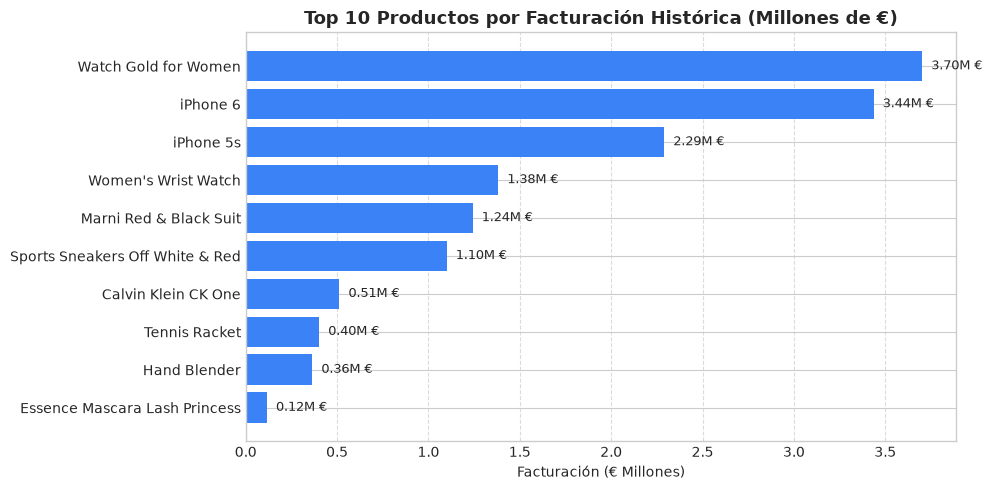

In [12]:
# Pregunta 1: ¿Cuáles son los 10 productos con mayor facturación histórica?
top10_prods = df_analytical.groupby(['product_id', 'title'], dropna=False)['revenue'].sum().reset_index()
top10_prods = top10_prods.sort_values(by='revenue', ascending=False).head(10)

print("1. Top 10 productos con mayor facturación histórica:")
display(top10_prods)

# Visualización Gráfica Q1
plt.figure(figsize=(10, 5))
labels_q1 = top10_prods['title'].fillna('ID ' + top10_prods['product_id'].astype(str))[::-1]
values_q1 = (top10_prods['revenue'] / 1e6)[::-1]
bars = plt.barh(labels_q1, values_q1, color='#3b82f6')
plt.title('Top 10 Productos por Facturación Histórica (Millones de €)', fontsize=13, fontweight='bold')
plt.xlabel('Facturación (€ Millones)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.05, bar.get_y() + bar.get_height()/2, f'{w:.2f}M €', va='center', fontsize=9)
plt.tight_layout()
plt.show()

2. Facturación por categorías:


,category,revenue
5,smartphones,5725665.83
8,womens-watches,5083265.29
7,womens-dresses,1241517.15
4,mens-shoes,1099569.32
1,fragrances,512040.87
6,sports-accessories,465797.90
9,Sin Categoría (Descatalogados),382062.85
3,kitchen-accessories,363804.95
0,beauty,115449.79
2,groceries,7130.90


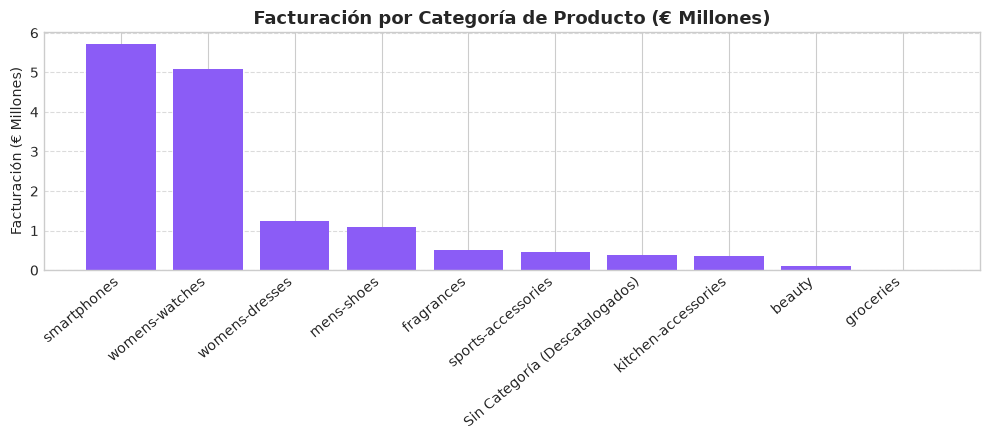

In [13]:
# Pregunta 2: ¿Qué categorías generan mayor facturación?
cat_rev = df_analytical.groupby('category', dropna=False)['revenue'].sum().reset_index()
cat_rev['category'] = cat_rev['category'].fillna('Sin Categoría (Descatalogados)')
cat_rev = cat_rev.sort_values(by='revenue', ascending=False)

print("2. Facturación por categorías:")
display(cat_rev)

# Visualización Gráfica Q2
plt.figure(figsize=(10, 4.5))
plt.bar(cat_rev['category'], cat_rev['revenue'] / 1e6, color='#8b5cf6')
plt.title('Facturación por Categoría de Producto (€ Millones)', fontsize=13, fontweight='bold')
plt.ylabel('Facturación (€ Millones)')
plt.xticks(rotation=40, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

3. Resumen de rendimiento por canal de venta:


,transacciones,unidades_vendidas,facturacion_total,pct_facturacion
channel,,,,
web,34517,55301,6905704.24,46.05
app,25610,41088,5113243.09,34.10
marketplace,8889,14290,1751124.86,11.68
store,5984,9672,1226232.66,8.18


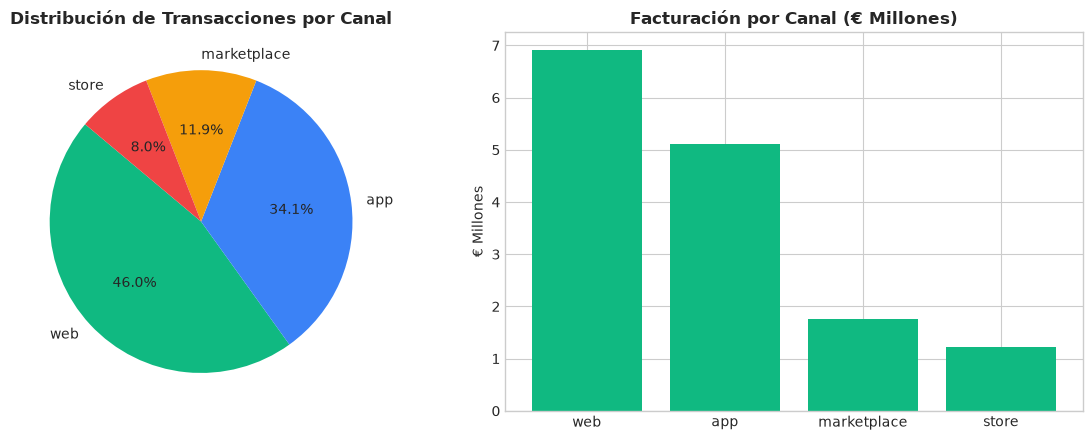

In [14]:
# Pregunta 3: ¿Qué canales concentran más ventas?
channel_summary = df_analytical.groupby('channel').agg(
    transacciones=('sale_id', 'count'),
    unidades_vendidas=('units', 'sum'),
    facturacion_total=('revenue', 'sum')
).sort_values(by='facturacion_total', ascending=False)

channel_summary['pct_facturacion'] = (channel_summary['facturacion_total'] / channel_summary['facturacion_total'].sum()) * 100

print("3. Resumen de rendimiento por canal de venta:")
display(channel_summary)

# Gráfico Q3
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].pie(channel_summary['transacciones'], labels=channel_summary.index, autopct='%1.1f%%', colors=['#10b981', '#3b82f6', '#f59e0b', '#ef4444'], startangle=140)
ax[0].set_title('Distribución de Transacciones por Canal', fontweight='bold')

ax[1].bar(channel_summary.index, channel_summary['facturacion_total'] / 1e6, color='#10b981')
ax[1].set_title('Facturación por Canal (€ Millones)', fontweight='bold')
ax[1].set_ylabel('€ Millones')
plt.tight_layout()
plt.show()

In [15]:
# Pregunta 4: ¿Qué productos tienen actualmente un precio superior al menor precio observado en la competencia?
comp_comparison = df_analytical[['product_id', 'title', 'current_price', 'competitor_min_price', 'price_difference', 'price_difference_%']].drop_duplicates().dropna(subset=['current_price', 'competitor_min_price'])

higher_price = comp_comparison[comp_comparison['price_difference'] > 0].sort_values(by='price_difference', ascending=False)

print(f"4. Productos más caros que el mínimo de la competencia ({len(higher_price)} productos detectados):")
display(higher_price)

4. Productos más caros que el mínimo de la competencia (10 productos detectados):

,product_id,title,current_price,competitor_min_price,price_difference,price_difference_%
9,193,Watch Gold for Women,799.99,749.00,50.99,6.81
1,122,iPhone 6,299.99,279.00,20.99,7.52
3,121,iPhone 5s,199.99,179.99,20.00,11.11
10,91,Sports Sneakers Off White & Red,119.99,109.99,10.00,9.09
15,152,Tennis Racket,49.99,46.90,3.09,6.59
6,61,Hand Blender,34.99,31.90,3.09,9.69
2,6,Calvin Klein CK One,49.99,47.90,2.09,4.36
23,1,Essence Mascara Lash Princess,9.99,8.89,1.10,12.37
33,151,Tennis Ball,6.99,5.99,1.00,16.69
0,31,Lemon,0.79,0.69,0.10,14.49


In [16]:
# Pregunta 5: ¿Qué productos presentan la mayor diferencia porcentual?
top_pct_diff = comp_comparison.sort_values(by='price_difference_%', ascending=False)

print("5. Productos ordenados por diferencia porcentual descendente:")
display(top_pct_diff)

5. Productos ordenados por diferencia porcentual descendente:


,product_id,title,current_price,competitor_min_price,price_difference,price_difference_%
33,151,Tennis Ball,6.99,5.99,1.00,16.69
0,31,Lemon,0.79,0.69,0.10,14.49
23,1,Essence Mascara Lash Princess,9.99,8.89,1.10,12.37
3,121,iPhone 5s,199.99,179.99,20.00,11.11
6,61,Hand Blender,34.99,31.90,3.09,9.69
10,91,Sports Sneakers Off White & Red,119.99,109.99,10.00,9.09
1,122,iPhone 6,299.99,279.00,20.99,7.52
9,193,Watch Gold for Women,799.99,749.00,50.99,6.81
15,152,Tennis Racket,49.99,46.90,3.09,6.59
2,6,Calvin Klein CK One,49.99,47.90,2.09,4.36


In [17]:
# Pregunta 6: ¿Qué porcentaje de las ventas corresponde a productos sin información de competencia?
no_comp_mask = df_analytical['competitor_min_price'].isna()
pct_no_comp_tx = (no_comp_mask.sum() / len(df_analytical)) * 100
pct_no_comp_rev = (df_analytical.loc[no_comp_mask, 'revenue'].sum() / df_analytical['revenue'].sum()) * 100

print("6. Cobertura de la competencia en ventas:")
print(f"  - Porcentaje de transacciones sin datos de competencia: {pct_no_comp_tx:.2f}% ({no_comp_mask.sum():,} de {len(df_analytical):,} ventas)")
print(f"  - Porcentaje de facturación sin datos de competencia: {pct_no_comp_rev:.2f}%")

6. Cobertura de la competencia en ventas:
  - Porcentaje de transacciones sin datos de competencia: 17.09% (12,816 de 75,000 ventas)
  - Porcentaje de facturación sin datos de competencia: 20.04%


In [18]:
# Pregunta 7: ¿Existen productos vendidos históricamente que actualmente aparecen sin stock?
out_of_stock = df_analytical[df_analytical['stock'] == 0][['product_id', 'title', 'stock', 'availabilityStatus']].drop_duplicates()

print("7. Productos vendidos históricamente que actualmente tienen stock = 0:")
display(out_of_stock)

7. Productos vendidos históricamente que actualmente tienen stock = 0:


,product_id,title,stock,availabilityStatus
9,193,Watch Gold for Women,0.00,Out of Stock


In [19]:
# Pregunta 8: ¿Qué productos históricos no aparecen actualmente en el catálogo?
no_catalog_prods = df_analytical[df_analytical['title'].isna()][['product_id']].drop_duplicates().sort_values(by='product_id')

print("8. Identificadores de productos históricos sin ficha en el catálogo actual:")
display(no_catalog_prods)

8. Identificadores de productos históricos sin ficha en el catálogo actual:


,product_id
27,9001
639,9002
63,9003
37,9004


> **Resumen ejecutivo del análisis de negocio:**
> 1. **Top Ventas:** El producto estrella en facturación histórica es **Watch Gold for Women (ID 193)** con más de 3,70M €, seguido del **iPhone 6 (ID 122)** con 3,43M €.
> 2. **Categorías clave:** Las dos categorías dominantes son `smartphones` (5,72M €) y `womens-watches` (5,08M €).
> 3. **Canales:** La **Web** y la **App** representan conjuntamente el **80,17%** de las transacciones y el 80,12% de los ingresos totales.
> 4. **Precios y Competitividad:** El 100% de los productos con seguimiento de competencia tienen un precio actual superior al mínimo de mercado. La mayor brecha porcentual la ostenta el producto **151 (+16.69%)**, seguido del **31 (+14.49%)** y del **1 (+12.37%)**.
> 5. **Vacíos de datos de competencia:** El **17,09%** de las transacciones carecen de datos de competidores (corresponden a productos sin seguimiento en PriceScope o descatalogados).
> 6. **Riesgo crítico de stock:** El producto número 1 en ventas históricas (**Watch Gold for Women**, ID 193) está **completamente agotado (`stock == 0`)**, lo cual supone un grave coste de oportunidad comercial.
> 7. **Productos descatalogados:** Los IDs **9001, 9002, 9003 y 9004** no constan en el catálogo DummyJSON actual.

## Parte 9: Validación Automatizada del Pipeline
Para garantizar la fiabilidad del dataset analítico y demostrar que no existen errores silenciosos de integración ni duplicaciones accidentales, implementamos una batería de aserciones (`assert`).

In [20]:
print("--- EJECUTANDO BATERÍA DE VALIDACIONES AUTOMATIZADAS ---")

# 1. Unicidad de la clave primaria
assert df_analytical['sale_id'].is_unique, "FALLO: Existen sale_id duplicados."
print("✔ 1. Unicidad de sale_id verificada.")

# 2. Ausencia de multiplicaciones accidentales de filas
assert len(df_analytical) == len(df_sales), f"FALLO: Filas esperadas {len(df_sales)}, obtenidas {len(df_analytical)}."
print("✔ 2. Conservación estricta de filas transaccionales (75.000 filas).")

# 3. Consistencia de valores positivos
assert (df_analytical['units'] > 0).all(), "FALLO: Se encontraron unidades vendidas no positivas."
assert (df_analytical['unit_price'] > 0).all(), "FALLO: Se encontraron unit_price no positivos."
print("✔ 3. Integridad de unidades y precios positivos validada.")

# 4. Coherencia de variables derivadas
revenue_check = np.isclose(df_analytical['revenue'], df_analytical['units'] * df_analytical['unit_price'])
assert revenue_check.all(), "FALLO: Inconsistencia en el cálculo de revenue."
print("✔ 4. Coherencia matemática de revenue validada.")

# 5. Coherencia de tipos de datos esenciales
assert pd.api.types.is_datetime64_any_dtype(df_analytical['date']), "FALLO: date no es datetime."
assert pd.api.types.is_numeric_dtype(df_analytical['revenue']), "FALLO: revenue no es numérico."
print("✔ 5. Verificación de tipos de datos correcta.")

print("\nTodas las comprobaciones de calidad han finalizado con éxito.")

--- EJECUTANDO BATERÍA DE VALIDACIONES AUTOMATIZADAS ---
✔ 1. Unicidad de sale_id verificada.
✔ 2. Conservación estricta de filas transaccionales (75.000 filas).
✔ 3. Integridad de unidades y precios positivos validada.
✔ 4. Coherencia matemática de revenue validada.
✔ 5. Verificación de tipos de datos correcta.

Todas las comprobaciones de calidad han finalizado con éxito.


## Parte 10: Exportación a Formato Parquet
Exportamos el dataset analítico final al formato columnar de alto rendimiento **Parquet** (`shopdata_analytical.parquet`) utilizando el motor `pyarrow`, y validamos su relectura.

In [21]:
parquet_output_path = "shopdata_analytical.parquet"

# Exportar a Parquet
df_analytical.to_parquet(parquet_output_path, engine="pyarrow", index=False)
print(f"Dataset analítico exportado satisfactoriamente en: {parquet_output_path}")

# Relectura y comprobación de metadatos
df_check = pd.read_parquet(parquet_output_path, engine="pyarrow")

print("\n--- Verificación del fichero Parquet recargado ---")
print(f"Filas recuperadas: {len(df_check):,}")
print(f"Columnas recuperadas: {len(df_check.columns)}")
print(f"Tamaño en disco: {os.path.getsize(parquet_output_path) / (1024*1024):.2f} MB")
print(f"Tamaño del CSV original: {os.path.getsize(csv_file_path) / (1024*1024):.2f} MB")
print(f"Reducción de tamaño: {(1 - os.path.getsize(parquet_output_path)/os.path.getsize(csv_file_path))*100:.1f}%")

assert len(df_check) == 75000, "Error en validación de filas del fichero Parquet."
assert len(df_check.columns) == df_analytical.shape[1], "Error en validación de columnas del fichero Parquet."
print("✔ Relectura de Parquet completamente validada.")

Dataset analítico exportado satisfactoriamente en: shopdata_analytical.parquet


--- Verificación del fichero Parquet recargado ---
Filas recuperadas: 75,000
Columnas recuperadas: 21
Tamaño en disco: 2.21 MB
Tamaño del CSV original: 3.56 MB
Reducción de tamaño: 37.9%
✔ Relectura de Parquet completamente validada.


## Parte 11: Diagrama del Pipeline de Datos
Representamos visualmente la arquitectura integral del flujo de datos implementado:

```mermaid
flowchart TD
    subgraph Fuentes ["1. Fuentes Heterogéneas"]
        A["shopdata_sales.csv<br/>(Histórico transacciones)"]
        B["API REST DummyJSON<br/>(Catálogo productos)"]
        C["competitor_prices.html<br/>(Web Scraping PriceScope)"]
    end

    subgraph Extraccion ["2. Ingestión y Extracción"]
        E1["Pandas read_csv<br/>Parseo de fechas"]
        E2["Requests + Paginación Dinámica<br/>(skip/limit leyendo total)"]
        E3["BeautifulSoup<br/>Normalización de precios"]
    end

    subgraph Agregacion ["3. Resolución de Cardinalidades"]
        AG1["df_sales<br/>(Clave: sale_id, N por producto)"]
        AG2["df_products<br/>(Clave: product_id, 1 por producto)"]
        AG3["df_competitors<br/>(N ofertas por producto)<br/>⬇ GroupBy + Agg ⬇<br/>df_comp_summary (1:1)"]
    end

    subgraph Integracion ["4. Integración y Enriquecimiento"]
        M1["Left Join: Ventas + Catálogo<br/>(Preservación de ventas históricas)"]
        M2["Left Join: + Resumen Competencia<br/>(Sin multiplicación de filas)"]
        DER["Variables Derivadas:<br/>• revenue<br/>• price_difference<br/>• price_difference_%"]
    end

    subgraph Validacion ["5. Calidad y Almacenamiento"]
        VAL["Validación Automatizada<br/>(asserts de unicidad, tipos, coherencia)"]
        OUT[("shopdata_analytical.parquet<br/>(Formato columnar optimizado)")]
    end

    A --> E1 --> AG1 --> M1
    B --> E2 --> AG2 --> M1
    C --> E3 --> AG3 --> M2
    M1 --> M2 --> DER --> VAL --> OUT
```

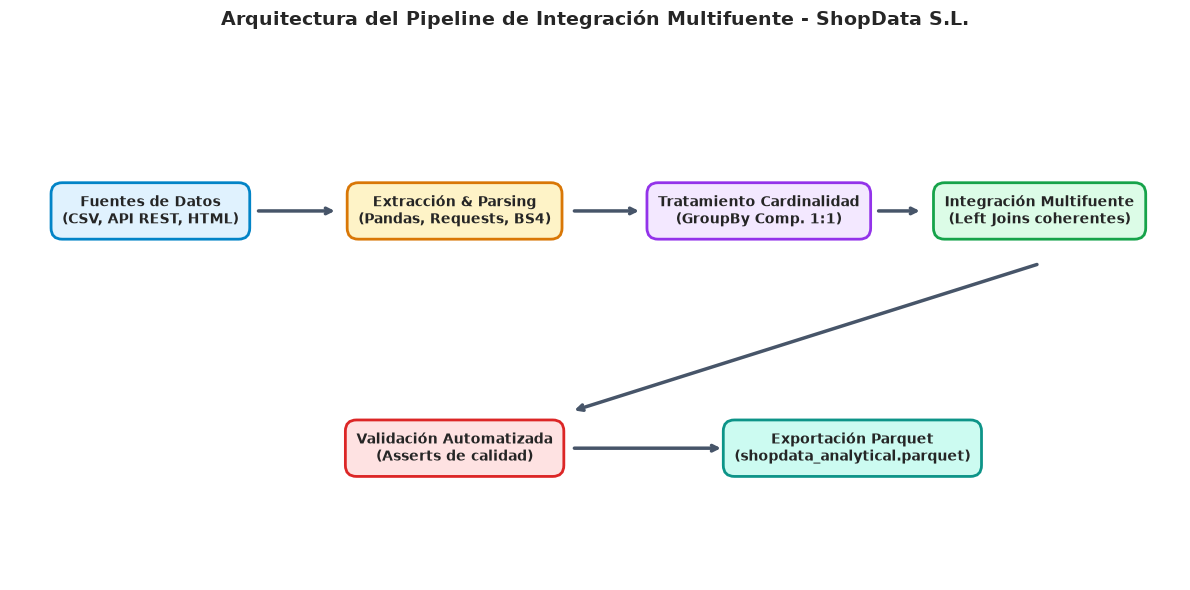

Diagrama generado y guardado como 'pipeline_diagram.png'.


In [22]:
# Generación y guardado del diagrama arquitectónico como imagen para la entrega
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis('off')

# Dibujamos cajas representativas
boxes = [
    ("Fuentes de Datos\n(CSV, API REST, HTML)", 0.12, 0.7, '#e0f2fe', '#0284c7'),
    ("Extracción & Parsing\n(Pandas, Requests, BS4)", 0.38, 0.7, '#fef3c7', '#d97706'),
    ("Tratamiento Cardinalidad\n(GroupBy Comp. 1:1)", 0.64, 0.7, '#f3e8ff', '#9333ea'),
    ("Integración Multifuente\n(Left Joins coherentes)", 0.88, 0.7, '#dcfce7', '#16a34a'),
    ("Validación Automatizada\n(Asserts de calidad)", 0.38, 0.25, '#fee2e2', '#dc2626'),
    ("Exportación Parquet\n(shopdata_analytical.parquet)", 0.72, 0.25, '#ccfbf1', '#0d9488'),
]

for title, x, y, fc, ec in boxes:
    ax.text(x, y, title, ha='center', va='center', bbox=dict(boxstyle='round,pad=0.8', facecolor=fc, edgecolor=ec, lw=2), fontsize=10, fontweight='bold')

# Flechas conectores
arrows = [
    ((0.21, 0.7), (0.28, 0.7)),
    ((0.48, 0.7), (0.54, 0.7)),
    ((0.74, 0.7), (0.78, 0.7)),
    ((0.88, 0.6), (0.48, 0.32)),
    ((0.48, 0.25), (0.61, 0.25)),
]

for start, end in arrows:
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=2.5, color='#475569'))

plt.title("Arquitectura del Pipeline de Integración Multifuente - ShopData S.L.", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("pipeline_diagram.png", dpi=300)
plt.show()
print("Diagrama generado y guardado como 'pipeline_diagram.png'.")

## Parte 12: Preguntas de Reflexión Final

### 1. ¿Cuál de las tres fuentes fue más difícil de procesar?
La fuente más compleja de procesar fue la **Fuente C (Web Scraping de `competitor_prices.html`)**. A diferencia de los datos tabulares delimitados (CSV) o los datos semiestructurados con esquema JSON (API REST), el HTML carece de tipos de datos nativos. Requiere inspeccionar selectores del DOM, extraer texto no homogéneo y aplicar expresiones regulares para desinfectar monedas dispares (`€`, `EUR`, caracteres especiales) y normalizar separadores decimales (comas a puntos).

### 2. ¿Por qué recibir un código HTTP 200 no garantiza haber descargado todo el catálogo?
Un código HTTP 200 únicamente certifica que el servidor web recibió y procesó la petición individual con éxito. Sin embargo, en arquitecturas REST los catálogos están **paginados** para optimizar la transferencia de red. La primera respuesta solo contiene un subconjunto (por defecto 30 elementos en DummyJSON). Para descargar el catálogo completo es imprescindible inspeccionar metadatos de respuesta (`total`, `skip`, `limit`) e iterar programáticamente hasta que el acumulado alcance el total real.

### 3. ¿Por qué no sería recomendable relacionar los productos utilizando únicamente su nombre?
Vincular registros mediante cadenas de texto libres es extremadamente propenso a errores:
- Variaciones de redacción, erratas ortográficas o nombres comerciales abreviados (ej. *'Calvin Klein CK One'* vs *'Calvin Klein CK ONE Eau de Toilette'*).
- Presencia de caracteres invisibles, espacios dobles o mayúsculas/minúsculas.
- Cambios de denominación en campañas comerciales sin cambio de artículo.
El uso de una clave subrogada o identificador numérico inmutable (`product_id`) garantiza la integridad referencial y un rendimiento de join en memoria infinitamente superior ($O(1)$ frente a comparaciones difusas de strings).

### 4. ¿Qué problema provoca una relación 1:N al realizar un merge?
Si se unen directamente dos tablas sobre una relación $1:N$ (o $N:M$) sin agregación previa, se produce una **multiplicación de filas (producto cartesiano de correspondencias)**. En nuestro caso, como un producto tiene múltiples ofertas de competidores, cada una de las 75.000 ventas se habría duplicado por cada competidor disponible, arruinando los totales contables, duplicando facturación y generando falsas transacciones en el dataset analítico.

### 5. ¿Qué diferencia existe entre un inner join y un left join en este problema?
- **Inner Join:** Descarta cualquier fila que no tenga correspondencia exacta en ambas tablas. En este proyecto habría provocado la pérdida inmediata de todas las ventas de los productos `9001, 9002, 9003 y 9004`.
- **Left Join:** Conserva la totalidad de las filas de la tabla izquierda (ventas), rellenando con `NaN` las columnas del catálogo si el producto ya no existe. Esto permite salvaguardar el 100% del historial financiero de la empresa.

### 6. ¿Por qué pueden existir ventas cuyo producto ya no aparece en el catálogo?
En cualquier comercio electrónico los catálogos son snapshots del estado vigente. A lo largo del tiempo, los artículos agotan su stock de forma definitiva, se descatalogan, cambian de proveedor, o finalizan promociones temporales. Por ello, el histórico transaccional conserva registros de productos que ya no existen en la API del catálogo actual.

### 7. ¿Qué riesgos tendría depender del HTML de una web real?
- **Fragilidad de selectores:** Cualquier rediseño estético o cambio en las clases CSS del frontend rompe inmediatamente el parser de scraping.
- **Mecanismos antibot:** Bloqueos por IP, rate limiting, CAPTCHAs o Cloudflare.
- **Renderizado del lado del cliente (CSR):** Si la web utiliza React/Vue, el HTML estático puede no contener los datos hasta que se ejecute JavaScript (requiriendo navegadores headless como Playwright o Selenium).
- **Problemas legales y éticos:** Términos de servicio que prohíben la extracción automatizada.

### 8. ¿Por qué es importante validar el número de filas después de cada integración?
Porque es el indicador más directo e inequívoco de salud estructural en un pipeline de datos. Un aumento inesperado de filas delata un problema de cardinalidad (duplicación por relación $1:N$ inadvertida), mientras que una disminución revela un *join* demasiado restrictivo (*inner join* o falta de coincidencia de claves) que destruye información sin lanzar excepciones en Python.

## Parte 22: Pregunta Final

### *«Python ejecuta: `pd.merge()` sin generar ninguna excepción. ¿Significa esto que la integración es correcta?»*

**Respuesta fundamentada:**

**No, rotunda y categóricamente NO.**  
Que `pd.merge()` se ejecute sin arrojar excepciones de Python solo indica que la sintaxis es válida y que los tipos de datos en memoria fueron operables a nivel de bajo nivel. En ningún caso garantiza la corrección semántica ni analítica de los datos.

Una integración aparentemente limpia puede contener fallos críticos de integridad:

1. **Incompatibilidad o desalineación de claves:**  
   Si las claves tienen sutiles diferencias (por ejemplo espacios en blanco accidentales, diferente capitalización o tipos `int` frente a `string`), el merge se ejecutará pero no emparejará ningún registro, dejando columnas repletas de `NaN` sin avisar.
2. **Ignorancia de la cardinalidad y duplicación masiva:**  
   Si la tabla de la derecha tiene filas repetidas para una misma clave (relación $1:N$) y se hace un merge sin agregar, Pandas multiplicará las filas de la tabla de la izquierda. La ejecución no falla, pero destruye las métricas del negocio duplicando o triplicando artificialmente facturación y unidades.
3. **Pérdida silenciosa de registros:**  
   Si por defecto se aplica un `inner join` sobre tablas con cobertura parcial, miles de transacciones se eliminan silenciosamente sin emitir advertencia alguna.
4. **Falsos positivos de cobertura:**  
   Si no se analiza el parámetro `indicator=True` o no se audita la tasa de valores nulos posterior a la integración, el pipeline producirá un dataset formalmente estructurado pero inútil para la toma de decisiones estratégicas.

Por estos motivos, la ejecución de `pd.merge()` debe considerarse únicamente el primer paso técnico, debiendo ser validada obligatoriamente mediante aserciones de unicidad, auditoría de filas antes y después, y comprobaciones matemáticas de coherencia.